# Figure: Duffing Oscillator and Van der Pol Oscillator

**Systems**
- Duffing: $\dot{x}=y,\ \dot{y}=-\delta y + \alpha x - \beta x^3$  
  ($\delta=0.3,\alpha=-1,\beta=1,\Delta t=0.1$)
- Van der Pol: $\dot{x}=y,\ \dot{y}=\mu(1-x^2)y - x$  
  ($\mu=1.1,\Delta t=0.1$)

**Outputs per system**
- EDMD matrix heatmaps (4-panel: Unordered / Incremental / PageRank / PPR)
- One-step error curve with IQR bands over `num_rnd` random seeds
- T-SSD scatter overlay
- Multi-step state prediction trajectories


In [ ]:
import sys, os
sys.path.insert(0, '../src')

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import expit
from math import comb
from functools import partial
import koopman_source as kp

plt.rcParams.update({
    "font.family": "sans-serif",
    "mathtext.fontset": "cm",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "axes.linewidth": 0.6,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

COLOR_UNO = '#AAAAAA'
COLOR_INC = '#2f9f47'
COLOR_PR  = '#2a6fb8'
COLOR_PPR = '#dd3d26'

SAVE_FIGS = False
FIG_DIR   = 'figures/'
os.makedirs(FIG_DIR, exist_ok=True)

# ── Number of random seeds for error-band plots ───────────────────────────────
# Set to 2-3 for quick checks; use 20 for publication-quality results.
num_rnd = 3

print(f'Setup done.  num_rnd = {num_rnd}')


Setup done.  num_rnd = 3


## Plotting helpers

In [12]:
def plot_error_with_bands(all_errors, N_vis, title, ax=None,
                           agg='median', band='iqr'):
    """Error curve with IQR / std bands from repeated experiments."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4.5))
    for name, color, marker in [
        ('Unordered',   COLOR_UNO, 'o'),
        ('Incremental', COLOR_INC, '^'),
        ('PageRank',    COLOR_PR,  's'),
        ('PPR',         COLOR_PPR, 'D'),
    ]:
        data = all_errors[name][:, :N_vis].copy()
        data[data <= 0] = np.nan
        xs = np.arange(1, N_vis + 1)

        if agg == 'median':
            center = np.nanmedian(data, axis=0)
            lo     = np.nanpercentile(data, 25, axis=0)
            hi     = np.nanpercentile(data, 75, axis=0)
        else:
            center = np.nanmean(data, axis=0)
            sd     = np.nanstd(data, axis=0)
            lo, hi = center - sd, center + sd

        valid = np.isfinite(center) & np.isfinite(lo) & np.isfinite(hi) & (lo > 0)
        ax.fill_between(xs[valid], lo[valid], hi[valid], color=color, alpha=0.18, lw=0)
        ax.semilogy(xs, center, color=color, lw=1.2,
                    marker=marker, ms=3.5, markevery=5,
                    markerfacecolor='white', markeredgecolor=color,
                    markeredgewidth=0.8, label=name)

    ax.set_xlabel('Sub-dictionary size $N$')
    ax.set_ylabel(r'$\|\mathbf{x}(t\!+\!1) - \hat{\mathbf{x}}(t\!+\!1)\|_2$')
    ax.set_title(title)
    ax.set_xlim(0, N_vis)
    ax.legend(framealpha=0.9, edgecolor='gray', fancybox=False, loc='lower right')
    ax.grid(True, ls='--', alpha=0.4, which='major')
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    return ax


def plot_state_pred(pred_data, title, ax=None, xlim=None, ylim=None):
    """Multi-step state prediction trajectories."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    true_traj = pred_data['True']
    n_pts = true_traj.shape[2]
    plot_methods = [
        ('Unordered',   COLOR_UNO, 'o', 0.8),
        ('Incremental', COLOR_INC, '^', 0.8),
        ('PageRank',    COLOR_PR,  's', 0.8),
        ('PPR',         COLOR_PPR, 'D', 0.8),
    ]
    for i in range(n_pts):
        ax.plot(true_traj[:, 0, i], true_traj[:, 1, i],
                color='#222222', ls='-', lw=0.9, alpha=0.5, zorder=2)
        for name, color, marker, lw in plot_methods:
            t = pred_data[name]
            ax.plot(t[:, 0, i], t[:, 1, i], color=color, ls='-', lw=lw, alpha=0.4, zorder=3)

    ax.scatter(true_traj[0, 0, :], true_traj[0, 1, :],
               marker='x', color='#222222', s=15, lw=1.2, zorder=5)
    for step in range(1, true_traj.shape[0]):
        label = 'True' if step == 1 else None
        ax.scatter(true_traj[step, 0, :], true_traj[step, 1, :],
                   marker='.', color='#222222', s=5, zorder=5, label=label)
    for name, color, marker, lw in plot_methods:
        t = pred_data[name]
        for step in range(1, t.shape[0]):
            label = name if step == 1 else None
            ax.scatter(t[step, 0, :], t[step, 1, :],
                       marker=marker, s=12, facecolors='none',
                       edgecolors=color, lw=0.5, alpha=0.9, label=label, zorder=5)

    ax.set_xlabel(r'$x$')
    ax.set_ylabel(r'$y$')
    ax.set_title(title)
    if xlim: ax.set_xlim(xlim)
    if ylim: ax.set_ylim(ylim)
    ax.legend(framealpha=0.9, edgecolor='gray', fancybox=False, fontsize=7, ncol=2, loc='upper left')
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    return ax

print('Plotting helpers defined.')


Plotting helpers defined.


## System 1: Duffing Oscillator

In [13]:
np.random.seed(1234)
d_duf       = 2
max_order_duf = 12
M_duf       = 2000
N_duf       = int(comb(d_duf + max_order_duf, d_duf))
alpha_duf   = -1; beta_duf = 1; delta_duf = 0.3; dt_duf = 0.1

duffing_func = partial(kp.Duffing, alpha0=alpha_duf, beta0=beta_duf,
                        delta0=delta_duf, dt=dt_duf)
default_duf  = np.arange(1, d_duf + 1)

# ── Single reference run (heatmap + TSSD) ────────────────────────────────────
x_duf       = kp.data_dist(d_duf, M_duf, -2, 2, rndseed=1)
y_duf       = kp.matrix_evolution(x_duf, duffing_func)
Psi_X_duf   = kp.psi_evaluation_laguerre(x_duf, d_duf, max_order_duf)
Psi_Y_duf   = kp.psi_evaluation_laguerre(y_duf, d_duf, max_order_duf)
K_duf       = kp.find_best_lin(Psi_X_duf, Psi_Y_duf)

x_duf_test  = kp.data_dist(d_duf, M_duf, -2, 2, rndseed=1234)
y_duf_test  = kp.matrix_evolution(x_duf_test, duffing_func)
Psi_X_duf_t = kp.psi_evaluation_laguerre(x_duf_test, d_duf, max_order_duf)
Psi_Y_duf_t = kp.psi_evaluation_laguerre(y_duf_test, d_duf, max_order_duf)

methods_duf = kp.compute_orderings(K_duf, N_duf, d_duf, default_duf, Psi_X_duf, Psi_Y_duf)
errors_duf  = kp.compute_errors(methods_duf, Psi_X_duf, Psi_Y_duf,
                                 Psi_X_duf_t, Psi_Y_duf_t, d_duf, N_duf, default_duf)

# ── Multi-seed error bands ────────────────────────────────────────────────────
print(f'Running Duffing multi-seed (num_rnd={num_rnd})...')
all_errors_duf = kp.compute_errors_multiseed(
    d_duf, max_order_duf, M_duf, -2, 2,
    duffing_func, default_duf, num_rnd=num_rnd
)
print('Done.')

# ── T-SSD epsilon sweep ───────────────────────────────────────────────────────
tssd_eps_duf  = np.linspace(0.0, 1.0, 100)
tssd_res_duf  = kp.compute_tssd_errors(
    Psi_X_duf, Psi_Y_duf, Psi_X_duf_t, Psi_Y_duf_t,
    default_duf, epsilons=tssd_eps_duf
)

print(f'Duffing: N={N_duf}')
for name in ['Unordered', 'Incremental', 'PageRank', 'PPR']:
    e = errors_duf[name]
    print(f'  {name:12s}: min={np.nanmin(e):.2e} at N={np.nanargmin(e)+1}')


Running Duffing multi-seed (num_rnd=3)...
Done.
Duffing: N=91
  Unordered   : min=5.93e-05 at N=64
  Incremental : min=4.16e-13 at N=8
  PageRank    : min=6.23e-13 at N=6
  PPR         : min=4.55e-13 at N=6


### Duffing — heatmaps

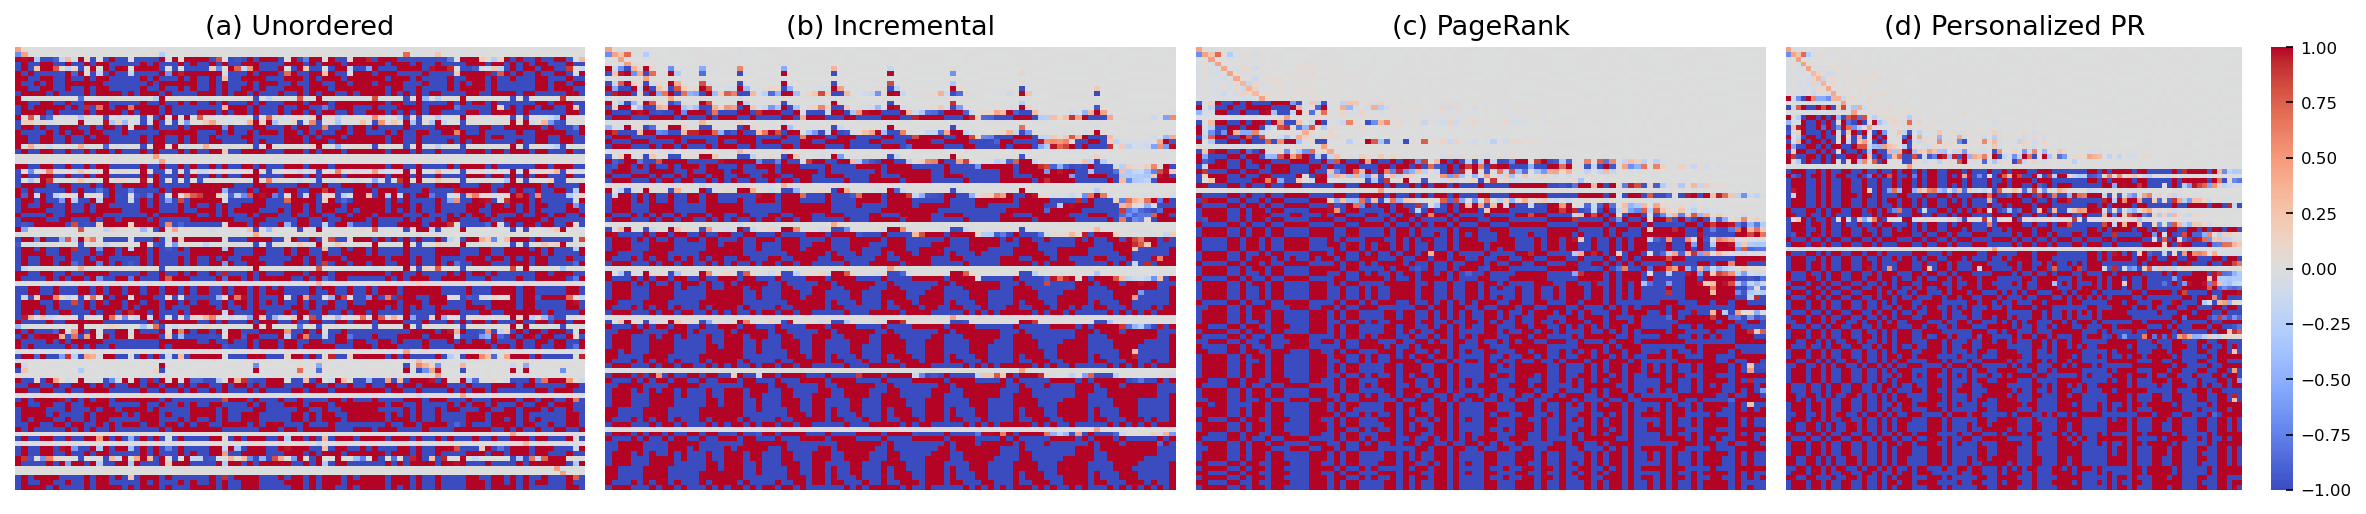

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (name, label) in zip(axes, [
    ('Unordered',   '(a) Unordered'),
    ('Incremental', '(b) Incremental'),
    ('PageRank',    '(c) PageRank'),
    ('PPR',         '(d) Personalized PR'),
]):
    K_perm = K_duf[np.ix_(methods_duf[name], methods_duf[name])]
    sns.heatmap(-1 + 2*expit(np.transpose(K_perm)), ax=ax,
                cmap='coolwarm', cbar=(name == 'PPR'),
                xticklabels=False, yticklabels=False)
    ax.set_title(label, fontsize=13)

plt.tight_layout()
if SAVE_FIGS:
    plt.savefig(f'{FIG_DIR}Duffing_heatmap.pdf', dpi=600, bbox_inches='tight')
plt.show()


### Duffing — error bands + state predictions

/var/folders/rp/2_84f17j5nqfkc989yrk6cq40000gn/T/ipykernel_16686/558201096.py:17: RuntimeWarning: All-NaN slice encountered
  center = np.nanmedian(data, axis=0)
/opt/anaconda3/envs/py_base/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


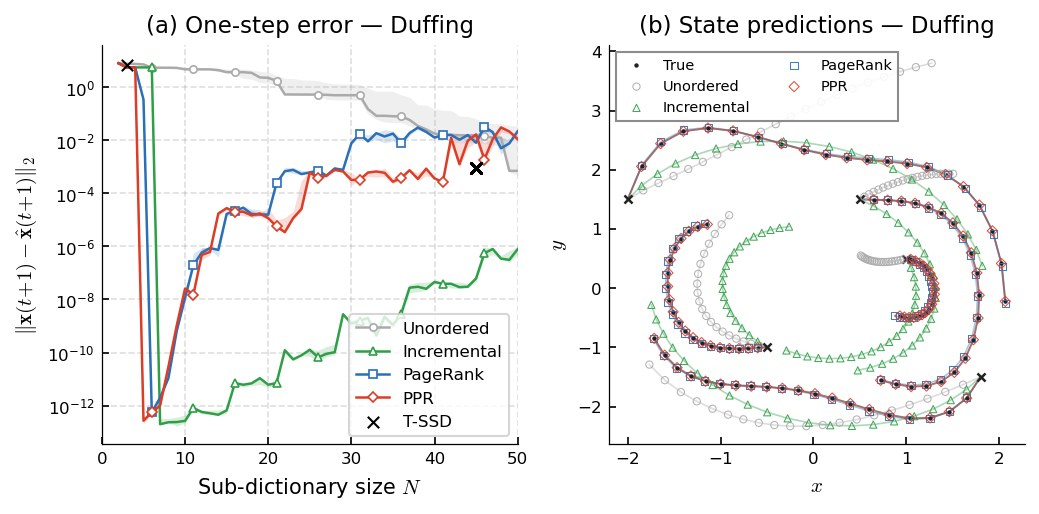

In [15]:
Nr_duf   = 5
pred_pts_duf = np.array([[-2.0,  0.5, -0.5, 1.0,  1.8],
                          [ 1.5,  1.5, -1.0, 0.5, -1.5]])
psi_eval_duf = lambda pts: kp.psi_evaluation_laguerre(pts, d_duf, max_order_duf)
pred_duf = kp.compute_state_predictions(
    methods_duf, Psi_X_duf, Psi_Y_duf, pred_pts_duf, d_duf,
    max_order_duf, default_duf, Nr_duf, duffing_func, 20, psi_eval_duf,
    orth_basis=True)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))

plot_error_with_bands(all_errors_duf, 50, '(a) One-step error — Duffing',
                      ax=axes[0], agg='median', band='iqr')
axes[0].scatter(tssd_res_duf[:, 1], tssd_res_duf[:, 2],
                c='black', marker='x', s=30, linewidths=1, zorder=5, label='T-SSD')
axes[0].legend(fontsize=8)

plot_state_pred(pred_duf, '(b) State predictions — Duffing', ax=axes[1])

plt.tight_layout()
if SAVE_FIGS:
    plt.savefig(f'{FIG_DIR}duffing_results.pdf', dpi=600, bbox_inches='tight')
plt.show()


## System 2: Van der Pol Oscillator

In [16]:
np.random.seed(123)
d_vdp         = 2
max_order_vdp = 12
M_vdp         = 2000
N_vdp         = int(comb(d_vdp + max_order_vdp, d_vdp))
mu_vdp        = 1.1
dt_vdp        = 0.1

vdp_func     = partial(kp.VanDerPol, mu0=mu_vdp, dt=dt_vdp)
default_vdp  = np.arange(1, d_vdp + 1)

# ── Single reference run ──────────────────────────────────────────────────────
x_vdp       = kp.data_dist(d_vdp, M_vdp, -3, 3, rndseed=1)
y_vdp       = kp.matrix_evolution(x_vdp, vdp_func)
Psi_X_vdp   = kp.psi_evaluation_laguerre(x_vdp, d_vdp, max_order_vdp)
Psi_Y_vdp   = kp.psi_evaluation_laguerre(y_vdp, d_vdp, max_order_vdp)
K_vdp       = kp.find_best_lin(Psi_X_vdp, Psi_Y_vdp)

x_vdp_test  = kp.data_dist(d_vdp, M_vdp, -3, 3, rndseed=20)
y_vdp_test  = kp.matrix_evolution(x_vdp_test, vdp_func)
Psi_X_vdp_t = kp.psi_evaluation_laguerre(x_vdp_test, d_vdp, max_order_vdp)
Psi_Y_vdp_t = kp.psi_evaluation_laguerre(y_vdp_test, d_vdp, max_order_vdp)

methods_vdp = kp.compute_orderings(K_vdp, N_vdp, d_vdp, default_vdp, Psi_X_vdp, Psi_Y_vdp)
errors_vdp  = kp.compute_errors(methods_vdp, Psi_X_vdp, Psi_Y_vdp,
                                 Psi_X_vdp_t, Psi_Y_vdp_t, d_vdp, N_vdp, default_vdp)

# ── Multi-seed ────────────────────────────────────────────────────────────────
print(f'Running Van der Pol multi-seed (num_rnd={num_rnd})...')
all_errors_vdp = kp.compute_errors_multiseed(
    d_vdp, max_order_vdp, M_vdp, -3, 3,
    vdp_func, default_vdp, num_rnd=num_rnd
)
print('Done.')

# ── T-SSD ─────────────────────────────────────────────────────────────────────
tssd_eps_vdp  = np.linspace(0.0, 1.0, 100)
tssd_res_vdp  = kp.compute_tssd_errors(
    Psi_X_vdp, Psi_Y_vdp, Psi_X_vdp_t, Psi_Y_vdp_t,
    default_vdp, epsilons=tssd_eps_vdp
)

print(f'Van der Pol: N={N_vdp}')
for name in ['Unordered', 'Incremental', 'PageRank', 'PPR']:
    e = errors_vdp[name]
    print(f'  {name:12s}: min={np.nanmin(e):.2e} at N={np.nanargmin(e)+1}')


Running Van der Pol multi-seed (num_rnd=3)...
Done.
Van der Pol: N=91
  Unordered   : min=1.72e-04 at N=62
  Incremental : min=1.78e-13 at N=10
  PageRank    : min=1.78e-09 at N=18
  PPR         : min=1.30e-13 at N=6


### Van der Pol — heatmaps

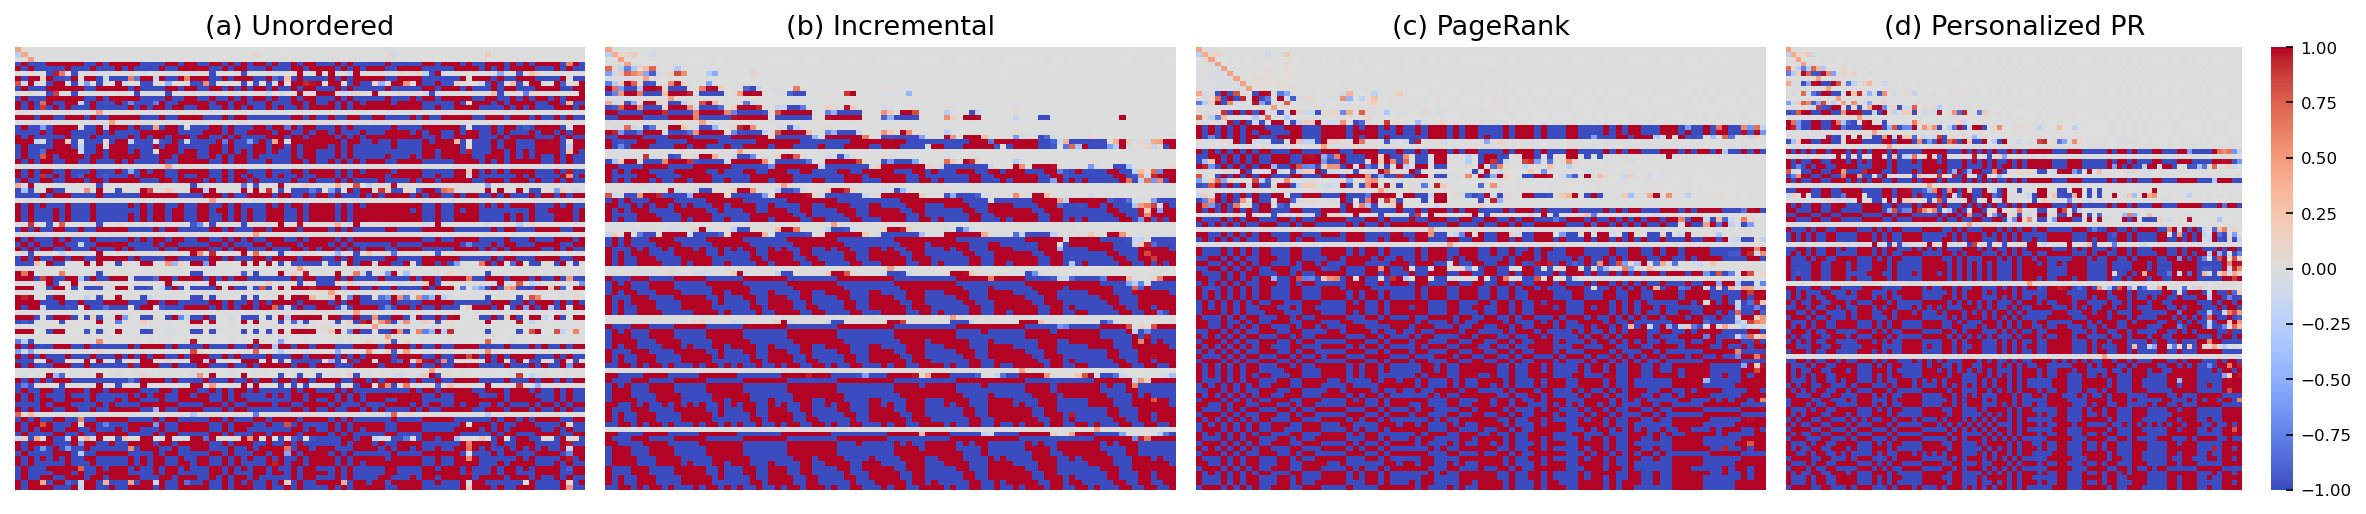

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (name, label) in zip(axes, [
    ('Unordered',   '(a) Unordered'),
    ('Incremental', '(b) Incremental'),
    ('PageRank',    '(c) PageRank'),
    ('PPR',         '(d) Personalized PR'),
]):
    K_perm = K_vdp[np.ix_(methods_vdp[name], methods_vdp[name])]
    sns.heatmap(-1 + 2*expit(np.transpose(K_perm)), ax=ax,
                cmap='coolwarm', cbar=(name == 'PPR'),
                xticklabels=False, yticklabels=False)
    ax.set_title(label, fontsize=13)

plt.tight_layout()
if SAVE_FIGS:
    plt.savefig(f'{FIG_DIR}VanDerPol_heatmap.pdf', dpi=600, bbox_inches='tight')
plt.show()


### Van der Pol — error bands + state predictions

/var/folders/rp/2_84f17j5nqfkc989yrk6cq40000gn/T/ipykernel_16686/558201096.py:17: RuntimeWarning: All-NaN slice encountered
  center = np.nanmedian(data, axis=0)
/opt/anaconda3/envs/py_base/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


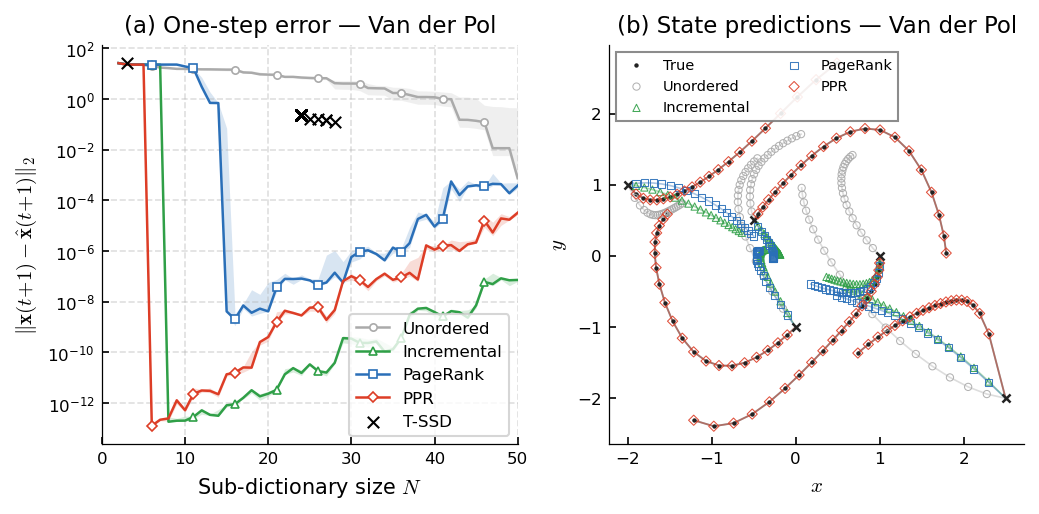

In [18]:
Nr_vdp   = 6
pred_pts_vdp = np.array([[-2.0, -0.5,  2.5,  0.0,  1.0],
                          [ 1.0,  0.5, -2.0, -1.0,  0.0]])
psi_eval_vdp = lambda pts: kp.psi_evaluation_laguerre(pts, d_vdp, max_order_vdp)
pred_vdp = kp.compute_state_predictions(
    methods_vdp, Psi_X_vdp, Psi_Y_vdp, pred_pts_vdp, d_vdp,
    max_order_vdp, default_vdp, Nr_vdp, vdp_func, 20, psi_eval_vdp,
    orth_basis=True)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))

plot_error_with_bands(all_errors_vdp, 50, '(a) One-step error — Van der Pol',
                      ax=axes[0], agg='median', band='iqr')
axes[0].scatter(tssd_res_vdp[:, 1], tssd_res_vdp[:, 2],
                c='black', marker='x', s=30, linewidths=1, zorder=5, label='T-SSD')
axes[0].legend(fontsize=8, loc='lower right')

plot_state_pred(pred_vdp, '(b) State predictions — Van der Pol', ax=axes[1])

plt.tight_layout()
if SAVE_FIGS:
    plt.savefig(f'{FIG_DIR}vdp_results.pdf', dpi=600, bbox_inches='tight')
plt.show()


## Summary table

In [19]:
print('=' * 90)
print(f'{"System":<18} {"N":>5} {"Unordered":>12} {"Incremental":>12} {"PageRank":>12} {"PPR":>12}')
print('=' * 90)
for sname, errs, N_sys in [('Duffing', errors_duf, N_duf),
                             ('Van der Pol', errors_vdp, N_vdp)]:
    vals = {nm: np.nanmin(errs[nm]) for nm in ['Unordered','Incremental','PageRank','PPR']}
    print(f"{sname:<18} {N_sys:>5} {vals['Unordered']:>12.2e} {vals['Incremental']:>12.2e} {vals['PageRank']:>12.2e} {vals['PPR']:>12.2e}")
print('=' * 90)


System                 N    Unordered  Incremental     PageRank          PPR
Duffing               91     5.93e-05     4.16e-13     6.23e-13     4.55e-13
Van der Pol           91     1.72e-04     1.78e-13     1.78e-09     1.30e-13
